# Chapter 8 - Capstone: the Bohol island, four scenarios

This final chapter puts every tool from the bootcamp into one decision-grade
study. We model the **whole Bohol island** over a full day and compare four
futures a planner would actually weigh:

| Scenario | Question it answers |
| --- | --- |
| **BAU** | What does today's diesel-and-import system cost and emit? |
| **+ Renewables** | What do 60 MW solar + 45 MW wind change? |
| **+ Battery** | Does a 20 MW / 4 h battery add value on top? |
| **Islanded** | If the submarine cable fails, does the island stay up? |

Every scenario is solved with `n.optimize()`; a high-cost "load-shedding"
generator stands in for unserved energy, so a shortfall shows up as **shed MWh**
instead of a solver failure - exactly how a real study flags a security risk.

**Goals of this chapter**
- Assemble the full dataset into one reusable builder.
- Compare scenarios on cost, CO2, renewable share and security.
- Read the recommended dispatch and the island network on a map.

In [1]:
import warnings, logging
warnings.filterwarnings("ignore")
for _n in ("pypsa", "linopy"):
    logging.getLogger(_n).setLevel(logging.ERROR)

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pypsa

DATA = next(p for p in [Path("data"), Path("../data"), Path("pypsa-bootcamp/data")]
            if (p / "PyPSA_Dataset_Bohol.xlsx").exists())
XLS = DATA / "PyPSA_Dataset_Bohol.xlsx"
FIG = next(p for p in [Path("figures"), Path("../figures")] if p.exists())

buses = pd.read_excel(XLS, "buses")
lines = pd.read_excel(XLS, "lines")
carriers = pd.read_excel(XLS, "carriers")
gens = pd.read_excel(XLS, "generators")
loads_t = pd.read_excel(XLS, "loads_t", index_col=0)
gens_t = pd.read_excel(XLS, "generators_t", index_col=0)
MC = {c.name: c.VOM + c.fuel / c.efficiency for c in carriers.itertuples()}
CO2 = dict(zip(carriers.name, carriers.co2_emissions))
COLORS = dict(zip(carriers.name, carriers.color))
OPT = dict(solver_name="highs", solver_options={"output_flag": False}, log_to_console=False)

### 8.1 One builder for every scenario

Flags turn each option on or off. `VOLL` (value of lost load) is the make-believe
price of shedding - far above any real generator, so the solver sheds only when it
physically must, and the amount shed measures the security gap.

In [2]:
VOLL = 5000.0   # currency per MWh of unserved energy

def bohol(renewables=False, battery=False, islanded=False):
    n = pypsa.Network()
    n.set_snapshots(loads_t.index)
    for b in buses.itertuples():
        n.add("Bus", b.name, v_nom=b.v_nom, x=b.x, y=b.y)
    for c in carriers.itertuples():
        n.add("Carrier", c.name, co2_emissions=c.co2_emissions, color=c.color)
    for l in lines.itertuples():
        n.add("Line", l.name, bus0=l.bus0, bus1=l.bus1, r=l.r, x=l.x, s_nom=l.s_nom)
    # existing fleet; the grid cable is lost when islanded
    for g in gens.itertuples():
        p_nom = 0.0 if (g.carrier == "Grid" and islanded) else g.p_nom
        n.add("Generator", g.name, bus=g.bus, carrier=g.carrier,
              p_nom=p_nom, marginal_cost=MC[g.carrier])
    if renewables:
        n.add("Generator", "SOLAR", bus="07TAPAL", carrier="Solar", p_nom=60,
              marginal_cost=MC["Solar"], p_max_pu=gens_t["SOLAR_BOHOL"].values)
        n.add("Generator", "WIND", bus="07UBAY", carrier="Wind", p_nom=45,
              marginal_cost=MC["Wind"], p_max_pu=gens_t["WIND_BOHOL"].values)
    if battery:
        n.add("StorageUnit", "BATTERY", bus="07UBAY", carrier="Battery", p_nom=20,
              max_hours=4, marginal_cost=0.0, efficiency_dispatch=0.95,
              efficiency_store=1.0, cyclic_state_of_charge=True)
    # load-shedding proxy at each load bus (not a real plant)
    for b in ["07CORELLA", "07UBAY"]:
        n.add("Generator", "shed_" + b, bus=b, carrier="Grid", p_nom=300,
              marginal_cost=VOLL)
    for bus, col, name in [("07CORELLA", "07CORELLA_LOAD", "Load_Corella"),
                           ("07UBAY", "07UBAY_LOAD", "Load_Ubay")]:
        n.add("Load", name, bus=bus, p_set=loads_t[col].values)
    return n

### 8.2 A KPI reader

From a solved network we pull the numbers a decision rests on: real operating
cost (excluding the fictitious shedding), CO2, renewable share, fuel use and any
unserved energy.

In [3]:
def kpis(n):
    p = n.generators_t.p
    is_shed = p.columns.str.startswith("shed_")
    real = p.loc[:, ~is_shed]
    shed_mwh = p.loc[:, is_shed].to_numpy().sum()
    carrier = n.generators.carrier
    energy = real.T.groupby(carrier[real.columns]).sum().T.sum()
    demand = n.loads_t.p.to_numpy().sum()
    op_cost = (real.sum() * n.generators.marginal_cost[real.columns]).sum()
    co2 = float((real.sum() * carrier[real.columns].map(CO2)).sum())
    renew = energy.get("Solar", 0.0) + energy.get("Wind", 0.0)
    return {
        "op cost": round(op_cost),
        "CO2 (t)": round(co2, 1),
        "renew %": round(100 * renew / demand, 1),
        "diesel MWh": round(energy.get("Diesel", 0.0)),
        "grid MWh": round(energy.get("Grid", 0.0)),
        "shed MWh": round(shed_mwh, 1),
    }

### 8.3 Run the four scenarios

In [4]:
scenarios = {
    "BAU (diesel + import)": bohol(),
    "+ Renewables": bohol(renewables=True),
    "+ Renewables + Battery": bohol(renewables=True, battery=True),
    "Islanded (cable lost)": bohol(renewables=True, battery=True, islanded=True),
}
table = {}
for name, n in scenarios.items():
    n.optimize(**OPT)
    table[name] = kpis(n)

summary = pd.DataFrame(table).T
print(summary.to_string())

                        op cost  CO2 (t)  renew %  diesel MWh  grid MWh  shed MWh
BAU (diesel + import)   54612.0    140.6      0.0         0.0    1278.0       0.0
+ Renewables            17289.0     42.0     59.1         0.0     382.0       0.0
+ Renewables + Battery  14169.0     33.6     64.4         0.0     306.0       0.0
Islanded (cable lost)   49268.0     78.6     64.4       306.0       0.0       0.0


**Read the table.**

- **Renewables transform the economics**: operating cost falls from ~54,600 to
  ~17,300 per day (about **-68 %**) and CO2 from ~141 to ~42 tonnes, as 60 MW of
  solar and 45 MW of wind displace imported and diesel energy.
- **The battery adds a further ~18 %** cost cut and lifts the renewable share to
  ~64 %, by shifting midday surplus into the evening (Chapter 5's lesson, now in a
  full system).
- **The island survives the cable loss with zero shed energy**: local diesel,
  hydro, renewables and the battery cover every hour. It is dearer (diesel is
  expensive) but the lights stay on - a concrete N-security result.

### 8.4 The recommended dispatch, hour by hour

The "+ Renewables + Battery" plan is the everyday recommendation. Here is how it
serves the day.

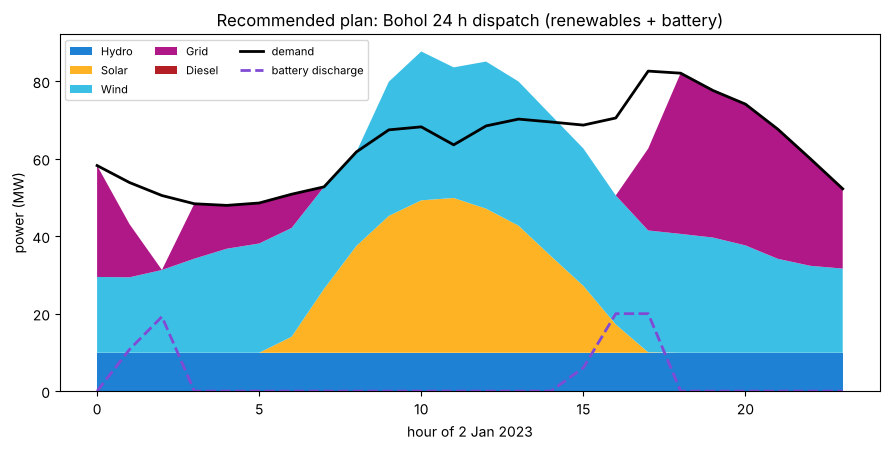

saved figures/08_recommended_dispatch.png


In [5]:
rec = scenarios["+ Renewables + Battery"]
order = ["Hydro", "Solar", "Wind", "Grid", "Diesel"]
p = rec.generators_t.p
p = p.loc[:, ~p.columns.str.startswith("shed_")]
stack = p.T.groupby(rec.generators.carrier[p.columns]).sum().T.reindex(columns=order, fill_value=0.0)
batt = rec.storage_units_t.p["BATTERY"]
hours = range(24)

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.stackplot(hours, [stack[c].values for c in order], labels=order,
             colors=[COLORS[c] for c in order])
ax.plot(hours, rec.loads_t.p.sum(axis=1).values, "k-", lw=2, label="demand")
ax.plot(hours, batt.clip(lower=0).values, "--", color=COLORS["Battery"], lw=2,
        label="battery discharge")
ax.set_xlabel("hour of 2 Jan 2023"); ax.set_ylabel("power (MW)")
ax.set_title("Recommended plan: Bohol 24 h dispatch (renewables + battery)")
ax.legend(ncol=3, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "08_recommended_dispatch.png", dpi=130); plt.show()
print("saved figures/08_recommended_dispatch.png")

### 8.5 The island on a map

Using the real coordinates in the dataset, we draw the three buses and the lines
between them - the physical system behind all the numbers.

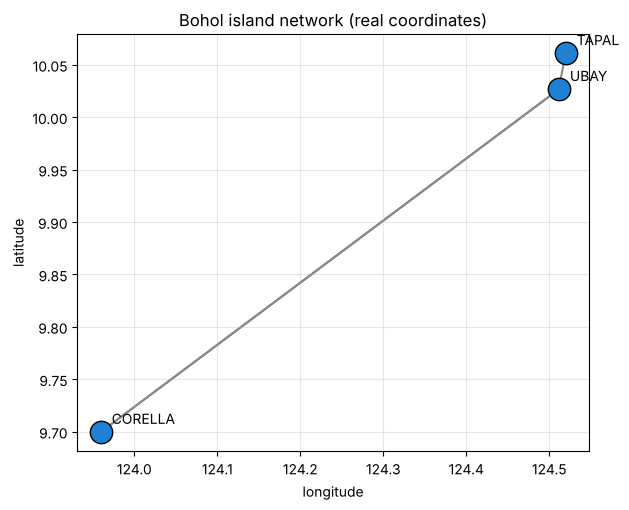

saved figures/08_network_map.png


In [6]:
fig, ax = plt.subplots(figsize=(6.4, 5.2))
for l in lines.itertuples():
    b0, b1 = buses.set_index("name").loc[l.bus0], buses.set_index("name").loc[l.bus1]
    ax.plot([b0.x, b1.x], [b0.y, b1.y], "-", color="#888", lw=1.5, zorder=1)
sizes = loads_t.max()  # peak load as a marker-size hint
for b in buses.itertuples():
    ax.scatter(b.x, b.y, s=260, color="#1E81D4", edgecolor="k", zorder=2)
    ax.annotate(b.name.replace("07", ""), (b.x, b.y),
                textcoords="offset points", xytext=(8, 6), fontsize=10)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("Bohol island network (real coordinates)")
ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG / "08_network_map.png", dpi=130); plt.show()
print("saved figures/08_network_map.png")

## Summary of the capstone

- One dataset, one builder, four scenarios: the bootcamp's full toolkit on a real
  island.
- **Renewables cut operating cost ~68 % and CO2 ~70 %**; a **battery adds another
  ~18 %** and lifts the renewable share to ~64 %.
- **The island rides through the loss of its submarine cable with no load shed** -
  costlier, but secure.
- The recommended everyday plan is clear from the numbers and the dispatch chart,
  and you built every piece of the reasoning yourself.

### Where to go next
- Swap in a full year of weather (8760 snapshots) instead of one day.
- Make capacities extendable (Chapter 7) to co-optimise build **and** operation.
- Add an N-1 security constraint (Chapter 6) to the capacity plan.
- Plug in real Renewables.ninja profiles once you have an API token.

You now have the complete workflow: build, power flow, dispatch, time series,
storage, security and investment - the core of professional power-system analysis
with PyPSA.